# Week 6 (v3): rPPG → skin temperature on open data (Toadstool) + contact-PPG feasibility (PhysioNet)

**Why this week.** MCD-rPPG cannot show temperature skill: labels std 0.13 °C, no fevers, and the constant MAE (0.093 °C) is already below a clinical thermometer's ±0.2 °C laboratory accuracy. LVT access was not granted. This notebook moves to **open data where temperature actually varies**:

| Part | Data | Input | Target |
|---|---|---|---|
| A | **Toadstool** (Simula; 10 people, face webcam 640×480 @ 30 fps, Empatica E4) | rPPG + facial skin colour from the face video | **wrist skin temperature** (E4 `TEMP.csv`) |
| B | **PhysioNet wearable-device-dataset** (open, ODC-By; stress + cycling sessions) | contact PPG (E4 BVP) and HR | wrist skin temperature |

**Be explicit in the report:** this is **skin** temperature, not core/body temperature and not fever. It is the closest open proxy that lets us test whether pulse and face signals track temperature *changes*.

**Two tasks, both with leave-one-participant-out (LOPO) evaluation:**
- **Task 1, absolute:** predict wrist temperature in each 60 s window. This is between-person and hard; reference = constant (train median).
- **Task 2, change from own baseline:** predict ΔT from the person's first minutes, using features expressed as change from the same baseline. Reference = constant, plus a **time-only** model (skin temperature drifts during a session; physiology must beat the clock, not just the constant).

**Controls:**
- Positive control: rPPG HR vs E4 HR.
- Contact-PPG ceiling: E4 BVP/HR features.
- Physiology baseline: Buller et al. 2013 Kalman filter (ECTemp, heart rate → core temperature), used as a feature.

With 10 participants the bootstrap intervals will be wide; report them as they are.

### What changed in v3 (after the v2 run) — the synchronisation was wrong in v1 and v2
- **Video start time comes from Toadstool itself.** `participant_X_video_info.json` gives the video's `start_time`/`stop_time` in Unix time. For participant 0 the video starts **25.4 min after** the raw E4 recording, outside v1/v2's ±15 min search. v1 and v2 therefore paired each video with the *wrong part* of the wristband recording (mostly before the game). v3 maps every video frame to Unix time between `start_time` and `stop_time`, so there is no guessing.
- **Only true E4-format folders are used.** The `participant_X_sensor` files have no start-time/rate header (they start `33.75, 33.75, …`, resampled to ~59 Hz, probably the game's 60 Hz frame clock). v2 misread them (start 1970, negative rates) and used them for 3 people, which made v2 worse than v1. v3 uses `_sensor_raw` (standard E4 export) only.
- **Heart-rate cross-correlation is now a check, not the sync method.** It reports the correlation at the JSON start and the best lag within ±60 s.
- **Part B fixes.** Protocols (STRESS / AEROBIC / ANAEROBIC) are read from the exact folder name, not the dataset title. Subjects are keyed per protocol. Windows with an implausible wrist temperature (outside 25–40 °C: band off the wrist) are dropped.
- **Positive control** is reported for both the best-SNR signal and plain POS on the whole face.

### Earlier changes kept from v2
1. **Sensor folder.** Toadstool has two E4 folders per participant, `participant_X_sensor` and `participant_X_sensor_raw`. v1 silently used `_sensor_raw`, which does not start with the video, so heart-rate sync failed for 8/10 people and the rPPG check looked bad (12.6 BPM). v2 tries **both** folders and keeps the one whose heart rate lines up with the video.
2. **macOS junk files** (`__MACOSX/`, `._*`) in the zip are ignored.
3. **E4 reader** accepts a date-time start row. This fixes the Part B crash (`'2013-03-03 17:43:37'`).
4. **rPPG under game-screen light.** Face colour is corrected for the screen's flicker using a background patch. Then 4 face regions (whole face, forehead, two cheeks) × 2 methods (POS, CHROM) are computed, and the best signal (highest SNR) is picked in each window. New cache files (`*_v2.npz`); the first run re-extracts the videos (~3 min each).
5. **E4 warm-up.** The wristband's temperature sensor warms up on the skin for several minutes after it is put on, which looks like a "temperature rise" that no camera can see. Results are reported with and without the first `WARMUP_MIN` minutes of each recording.
6. A short **inspection cell** prints what the sensor folders and JSON files contain, for the report.

## 0. Setup
Everything large goes to the **Colab disk** (`/content`, deleted when the session ends). Only face videos, E4 files and caches are copied to **Drive**.

In [ ]:
import os, re, io, sys, json, glob, time, shutil, zipfile, subprocess, urllib.request, urllib.parse, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import signal as sps, stats
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import LeaveOneGroupOut
warnings.filterwarnings("ignore", category=RuntimeWarning); warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
try: display
except NameError: display = print

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not os.environ.get("W6_NO_DRIVE"):
    from google.colab import drive; drive.mount("/content/drive")

ENV = os.environ.get
LOCAL      = ENV("W6_LOCAL", "/content/w6_local")                       # Colab disk (temporary)
DRIVE_ROOT = ENV("W6_DRIVE_ROOT", "/content/drive/MyDrive/MCD_rPPG")
TOAD_DRIVE = ENV("W6_TOAD_DRIVE", "/content/drive/MyDrive/Toadstool")    # face videos + E4 files kept here
OUT_DIR    = ENV("W6_OUT_DIR", os.path.join(DRIVE_ROOT, "week6_outputs"))
TOAD_PAGE  = "https://datasets.simula.no/toadstool/"
TOAD_URL   = ENV("W6_TOAD_URL", "")      # leave empty: found on the page automatically; or paste the link
TOAD_ZIP_LOCAL = ENV("W6_TOAD_ZIP", "")  # optional: an already-downloaded zip
PHYSIO_ZIP_URL = "https://physionet.org/content/wearable-device-dataset/get-zip/1.0.1/"
PHYSIO_ZIP_LOCAL = ENV("W6_PHYSIO_ZIP", "")
RUN_PART_B = ENV("W6_RUN_PART_B", "1") == "1"

WIN_S    = float(ENV("W6_WIN_S", "60"))     # analysis window (s)
STRIDE_S = float(ENV("W6_STRIDE_S", "30"))
BASE_MIN = float(ENV("W6_BASE_MIN", "3"))   # Task 2 personal baseline (first minutes)
WARMUP_MIN = float(ENV("W6_WARMUP_MIN", "10"))  # E4 skin-temperature sensor warm-up excluded in the second analysis
MAX_LAG_S = float(ENV("W6_MAX_LAG", "60"))  # check range around the JSON start (s); full search if no JSON
SEED, N_BOOT = 43, 2000
for d in (LOCAL, TOAD_DRIVE, OUT_DIR): os.makedirs(d, exist_ok=True)
RESULTS = []
print("Colab disk free:", round(shutil.disk_usage("/content" if os.path.exists("/content") else LOCAL).free/1e9, 1), "GB")
print("Drive target:", TOAD_DRIVE, "| outputs:", OUT_DIR)

Mounted at /content/drive
Colab disk free: 115.5 GB
Drive target: /content/drive/MyDrive/Toadstool | outputs: /content/drive/MyDrive/MCD_rPPG/week6_outputs


## 1. Download Toadstool and keep only what is needed
1. Find the `toadstool.zip` link on the dataset page (or use `TOAD_URL`). Download it to the Colab disk with resume support.
2. List the zip without extracting it.
3. Extract text/CSV files and video files to the Colab disk.
4. Identify **face videos by resolution (640×480)**; the game-screen recordings are skipped.
5. Copy the face videos + E4 files to Drive.

On a re-run, if Drive already holds the files, steps 1–5 are skipped.

In [ ]:
VIDEO_EXT = (".avi", ".mp4", ".mkv", ".mov", ".webm")

def _junk(path):
    return "__MACOSX" in path or os.path.basename(path).startswith("._")

def drive_has_data():
    return any(not _junk(t) for t in glob.glob(os.path.join(TOAD_DRIVE, "**", "TEMP.csv"), recursive=True))

def ca_bundle_for(host, out=os.path.join(LOCAL, "ca_bundle.pem")):
    """Some servers don't send their intermediate certificate, so Python/wget can't verify them
    ('unable to get local issuer certificate'). Fetch that intermediate from the address the server's
    own certificate points to (AIA 'CA Issuers'), add it to the standard CA bundle, and keep
    verification ON."""
    import certifi, ssl
    leaf = subprocess.run(f"echo | openssl s_client -connect {host}:443 -servername {host} 2>/dev/null "
                          "| openssl x509 -noout -text", shell=True, capture_output=True, text=True).stdout
    m = re.search(r"CA Issuers - URI:(\S+)", leaf)
    pems = []
    if m:
        raw = urllib.request.urlopen(m.group(1), timeout=60).read()
        for args in (["openssl", "x509", "-inform", "DER"], ["openssl", "x509", "-inform", "PEM"],
                     ["openssl", "pkcs7", "-inform", "DER", "-print_certs"]):
            r = subprocess.run(args, input=raw, capture_output=True)
            if r.returncode == 0 and b"BEGIN CERTIFICATE" in r.stdout:
                pems.append(r.stdout.decode()); break
    with open(out, "w") as f:
        f.write(open(certifi.where()).read() + "\n" + "\n".join(pems))
    print(f"CA bundle for {host}: {'added intermediate from ' + m.group(1) if pems else 'no intermediate found (using standard bundle)'}")
    return out

def find_zip_link(page, cafile, name="toadstool.zip"):
    import ssl
    ctx = ssl.create_default_context(cafile=cafile)
    html = urllib.request.urlopen(urllib.request.Request(page, headers={"User-Agent": "Mozilla/5.0"}),
                                  timeout=60, context=ctx).read().decode("utf-8", "ignore")
    links = re.findall(r'href=["\']([^"\']+)["\']', html, flags=re.I)
    hits = [urllib.parse.urljoin(page, l) for l in links if l.lower().split("?")[0].endswith(name)]
    return hits[0] if hits else None

ZIP_PATH = TOAD_ZIP_LOCAL or os.path.join(LOCAL, "toadstool.zip")
if drive_has_data():
    print("Toadstool already on Drive -> skipping download.")
else:
    if not TOAD_ZIP_LOCAL:   # wget -c resumes a partial file and does nothing if it is already complete
        CA = ca_bundle_for(urllib.parse.urlparse(TOAD_PAGE).hostname)
        url = TOAD_URL or find_zip_link(TOAD_PAGE, CA)
        assert url, ("Could not find the toadstool.zip link on the page. Right-click the 'toadstool.zip' "
                     "download link -> Copy link address, and set TOAD_URL to it.")
        host = urllib.parse.urlparse(url).hostname
        if host != urllib.parse.urlparse(TOAD_PAGE).hostname:
            CA = ca_bundle_for(host)
        print("Downloading", url)
        r = subprocess.run(["wget", "-c", "-q", "--show-progress", f"--ca-certificate={CA}", "-O", ZIP_PATH, url])
        assert r.returncode == 0 and os.path.getsize(ZIP_PATH) > 1e6, "download failed (see wget message above)"
    zf = zipfile.ZipFile(ZIP_PATH)
    members = [m for m in zf.infolist() if not m.is_dir()]
    listing = pd.DataFrame({"name": [m.filename for m in members], "MB": [m.file_size / 1e6 for m in members]})
    listing["ext"] = listing["name"].str.extract(r"(\.[^./]+)$")[0].str.lower()
    print(f"{len(listing)} files, {listing.MB.sum()/1e3:.1f} GB uncompressed")
    display(listing.groupby("ext")["MB"].agg(["count", "sum"]).sort_values("sum", ascending=False).round(1))
    display(listing.sort_values("name").head(40))
    listing.to_csv(os.path.join(OUT_DIR, "toadstool_zip_listing.csv"), index=False)

Toadstool already on Drive -> skipping download.


In [ ]:
def ffprobe_video(path):
    r = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                        "stream=width,height,avg_frame_rate,nb_frames:format=duration:format_tags=creation_time",
                        "-of", "json", path], capture_output=True, text=True)
    j = json.loads(r.stdout or "{}"); s = (j.get("streams") or [{}])[0]; f = j.get("format", {})
    num, den = (s.get("avg_frame_rate", "0/1").split("/") + ["1"])[:2]
    return dict(width=s.get("width"), height=s.get("height"),
                fps=float(num) / float(den) if float(den or 1) else np.nan,
                duration=float(f.get("duration", "nan") or "nan"),
                creation_time=(f.get("tags") or {}).get("creation_time"))

RAW = os.path.join(LOCAL, "toadstool_raw")
if not drive_has_data():
    os.makedirs(RAW, exist_ok=True)
    keep = [m for m in members if m.filename.lower().endswith((".csv", ".txt", ".json", ".md", ".pdf", ".zip") + VIDEO_EXT)
            and not m.filename.startswith("__MACOSX") and not os.path.basename(m.filename).startswith("._")]
    print(f"Extracting {len(keep)} files ({sum(m.file_size for m in keep)/1e9:.1f} GB) to the Colab disk...")
    for m in keep:
        zf.extract(m, RAW)
    # Empatica exports often come as their own zip: unpack nested zips next to themselves
    for nz in glob.glob(os.path.join(RAW, "**", "*.zip"), recursive=True):
        with zipfile.ZipFile(nz) as z2:
            z2.extractall(os.path.splitext(nz)[0])
        os.remove(nz)
        print("  unpacked nested zip:", os.path.relpath(nz, RAW))
    vids = [p for p in glob.glob(os.path.join(RAW, "**", "*"), recursive=True) if p.lower().endswith(VIDEO_EXT) and not _junk(p)]
    vinfo = pd.DataFrame([{"path": p, **ffprobe_video(p)} for p in vids])
    vinfo["is_face"] = (vinfo.width == 640) & (vinfo.height == 480) & \
                       ~vinfo.path.str.contains("game|screen|mario|gameplay", case=False)
    display(vinfo[["path", "width", "height", "fps", "duration", "is_face"]])
    assert vinfo.is_face.any(), "No 640x480 video found: inspect the table above and set is_face manually."
    # copy E4/text files and face videos to Drive, preserving folders
    n = 0
    for p in glob.glob(os.path.join(RAW, "**", "*"), recursive=True):
        if os.path.isdir(p): continue
        is_vid = p.lower().endswith(VIDEO_EXT)
        if is_vid and not vinfo.loc[vinfo.path == p, "is_face"].any():
            continue
        dst = os.path.join(TOAD_DRIVE, os.path.relpath(p, RAW)); os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(p, dst); n += 1
    print(f"Copied {n} files to {TOAD_DRIVE}")
print("Drive copy size:", round(sum(os.path.getsize(p) for p in glob.glob(os.path.join(TOAD_DRIVE, '**', '*'), recursive=True)
                                    if os.path.isfile(p)) / 1e9, 2), "GB")

Drive copy size: 8.22 GB


## 2. Discover participants, read E4 files, extract rPPG from face videos
**Empatica E4 CSV format:** row 1 = start time (Unix seconds, UTC), row 2 = sampling rate (Hz), then samples. `TEMP` is 4 Hz (°C), `BVP` 64 Hz, `HR` 1 Hz (starts 10 s after the others).

**rPPG.** Each 1 s, a Haar face detector finds the face (with a centre-crop fallback). The mean RGB of the inner face is taken for every frame, and POS (Wang et al. 2017) is applied with a 0.7–3 Hz band-pass. Per-participant traces are cached on Drive, so this runs once (~3–6 min per participant).

In [ ]:
def _to_unix(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return pd.Timestamp(str(v).strip()).timestamp()

def read_e4(path):
    """Empatica E4 CSV: row 1 = start (Unix seconds, or a date-time string), row 2 = Hz, then samples.
    Falls back to a header + timestamp-column layout."""
    raw = pd.read_csv(path, header=None)
    try:
        t0, fs = _to_unix(raw.iloc[0, 0]), float(raw.iloc[1, 0])
        x = raw.iloc[2:].apply(pd.to_numeric, errors="coerce").to_numpy(float)
        t = t0 + np.arange(len(x)) / fs
    except Exception:
        d = pd.read_csv(path)
        tcol = next((c for c in d.columns if re.search(r"time|stamp|date", str(c), re.I)), d.columns[0])
        tt = pd.to_numeric(d[tcol], errors="coerce")
        if tt.notna().mean() > 0.9:
            t = tt.to_numpy(float); t = t / 1000 if np.nanmedian(t) > 1e11 else t
        else:
            t = pd.to_datetime(d[tcol]).astype("int64").to_numpy() / 1e9
        x = d.drop(columns=[tcol]).apply(pd.to_numeric, errors="coerce").to_numpy(float)
        fs = 1 / np.nanmedian(np.diff(t))
    x = x[:, 0] if x.ndim == 2 and x.shape[1] == 1 else x
    return t, x, fs

def load_e4(d, verbose=True):
    """Read TEMP/BVP/HR; skip (and report) any file whose time axis or values could not be read."""
    out = {}
    for k in ("TEMP", "BVP", "HR"):
        f = os.path.join(d, f"{k}.csv")
        if not os.path.exists(f): continue
        try:
            t, x, fs = read_e4(f)
        except Exception as e:
            if verbose: print(f"  skip {os.path.relpath(f, TOAD_DRIVE) if f.startswith(TOAD_DRIVE) else f}: {e}")
            continue
        x1 = x if np.ndim(x) == 1 else x[:, 0]
        good = np.isfinite(fs) and fs > 0 and np.isfinite(t).mean() > 0.9 and np.isfinite(x1).mean() > 0.5
        if not good:
            if verbose: print(f"  skip {f}: fs={fs}, finite times {np.isfinite(t).mean():.0%}, finite values {np.isfinite(x1).mean():.0%}")
            continue
        out[k] = (t, x1, fs)
    return out

def is_e4_format(path):
    """True if row 1 is a Unix time (> 1e9) or a date-time, and row 2 a plausible sampling rate."""
    try:
        with open(path) as f:
            a, b = f.readline().split(",")[0].strip(), f.readline().split(",")[0].strip()
        t0, fs = _to_unix(a), float(b)
        return t0 > 1e9 and 0.5 <= fs <= 256
    except Exception:
        return False

def discover(root):
    """Participant = folder directly under the deepest common ancestor of all TEMP.csv folders.
    A participant may have several E4 folders (e.g. synced and raw); all are kept as candidates."""
    allt = sorted(t for t in glob.glob(os.path.join(root, "**", "TEMP.csv"), recursive=True) if not _junk(t))
    temps = [t for t in allt if is_e4_format(t)]
    skipped = sorted(set(os.path.basename(os.path.dirname(t)) for t in allt) - set(os.path.basename(os.path.dirname(t)) for t in temps))
    if skipped:
        print(f"Ignoring {len(skipped)} folder(s) without an E4 start-time/rate header, e.g. {skipped[:3]}")
    assert temps, f"No E4-format TEMP.csv under {root}"
    dirs = [os.path.dirname(t) for t in temps]
    common = os.path.commonpath(dirs) if len(set(dirs)) > 1 else os.path.dirname(dirs[0])
    parts = {}
    for d in dirs:
        rel = os.path.relpath(d, common)
        pid = rel.split(os.sep)[0] if rel != "." else os.path.basename(d)
        pdir = os.path.join(common, pid) if rel != "." else d
        parts.setdefault(pid, {"dir": pdir, "e4dirs": []})["e4dirs"].append(d)
    return parts

PARTS = discover(TOAD_DRIVE)
for pid, p in PARTS.items():
    v = [f for f in glob.glob(os.path.join(p["dir"], "**", "*"), recursive=True) if f.lower().endswith(VIDEO_EXT) and not _junk(f)]
    if not v:
        v = [f for f in glob.glob(os.path.join(TOAD_DRIVE, "**", "*"), recursive=True)
             if f.lower().endswith(VIDEO_EXT) and not _junk(f)
             and re.search(rf"(^|\D){re.escape(re.sub(r'\D', '', pid))}(\D|$)", os.path.basename(f))]
    p["video"] = max(v, key=os.path.getsize) if v else None
print(f"{len(PARTS)} participants")
rows = []
for pid, p in PARTS.items():
    vd = ffprobe_video(p["video"])["duration"] if p["video"] else np.nan
    for d in p["e4dirs"]:
        t, _, fs = read_e4(os.path.join(d, "TEMP.csv"))
        rows.append(dict(pid=pid, e4_folder=os.path.basename(d), temp_start_utc=pd.to_datetime(t[0], unit="s"),
                         temp_minutes=round((t[-1] - t[0]) / 60, 1), video_minutes=round(vd / 60, 1)))
display(pd.DataFrame(rows))

Ignoring 10 folder(s) without an E4 start-time/rate header, e.g. ['participant_0_sensor', 'participant_1_sensor', 'participant_2_sensor']
10 participants


,pid,e4_folder,temp_start_utc,temp_minutes,video_minutes
0,participant_0,participant_0_sensor_raw,2020-01-23 12:45:03,60.5,35.0
1,participant_1,participant_1_sensor_raw,2020-01-24 12:07:39,56.8,35.0
2,participant_2,participant_2_sensor_raw,2020-01-27 11:50:43,56.8,35.0
3,participant_3,participant_3_sensor_raw,2020-01-27 13:29:21,54.8,35.0
4,participant_4,participant_4_sensor_raw,2020-02-27 11:45:06,61.8,35.0
5,participant_5,participant_5_sensor_raw,2020-01-29 13:29:34,55.7,35.0
6,participant_6,participant_6_sensor_raw,2020-01-31 13:01:12,52.5,35.0
7,participant_7,participant_7_sensor_raw,2020-01-31 14:23:37,54.4,35.0
8,participant_8,participant_8_sensor_raw,2020-02-24 10:17:37,56.0,35.0
9,participant_9,participant_9_sensor_raw,2020-02-24 12:59:57,57.8,35.0


In [ ]:
# Inspection for the report: what is inside the sensor folders and JSON files (participant 0)
p0 = PARTS[sorted(PARTS)[0]]
for d in p0["e4dirs"]:
    print("==", os.path.relpath(d, TOAD_DRIVE), "|", sorted(f for f in os.listdir(d) if not f.startswith("._"))[:15])
    with open(os.path.join(d, "TEMP.csv")) as f:
        print("   TEMP.csv first lines:", [f.readline().strip() for _ in range(3)])
js = sorted(f for f in glob.glob(os.path.join(p0["dir"], "**", "*.json"), recursive=True) if not _junk(f))
for j in js[:3]:
    print("== json", os.path.relpath(j, TOAD_DRIVE), "|", open(j).read(300).replace("\n", " "))

== toadstool/participants/participant_0/participant_0_sensor_raw | ['ACC.csv', 'BVP.csv', 'EDA.csv', 'HR.csv', 'IBI.csv', 'TEMP.csv', 'info.txt', 'tags.csv']
   TEMP.csv first lines: ['1579783503.000000', '4.000000', '31.43']
== json toadstool/participants/participant_0/participant_0_gap_info.json | {"indices": [1915, 4400, 6453, 9978, 11502, 19713, 22313, 28088, 30645, 34621, 36686, 38471, 39795, 44983, 48810, 51042, 53051, 60969, 66053, 68181, 69592, 73600, 76088, 92863, 95884, 102986, 109534], "missing": 1540}
== json toadstool/participants/participant_0/participant_0_session.json | {"obs": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 130, 13
== json toadstool/participants/participant_0/participant_0_video_info.json | {"start_time": 1579785027.233

In [ ]:
import cv2
ROI_NAMES = ["face", "forehead", "cheek_l", "cheek_r"]

def _mean(img):
    return img.reshape(-1, 3).mean(0)[::-1] if img.size else np.full(3, np.nan)   # BGR -> RGB

def extract_rois(path, max_s=None):
    """Per frame mean RGB of 4 face regions + a background patch (top corners, away from the face)."""
    cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    try:
        det = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    except AttributeError:
        det = None; print("  (no Haar detector in this OpenCV build: using a centre crop)")
    out = {k: [] for k in ROI_NAMES + ["bg"]}; found, box, i = [], None, 0
    step = max(1, int(round(fps)))
    while True:
        ok, fr = cap.read()
        if not ok or (max_s and i > max_s * fps): break
        H, W = fr.shape[:2]
        if i % step == 0:
            small = cv2.resize(fr, None, fx=0.5, fy=0.5)
            f = det.detectMultiScale(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), 1.1, 5, minSize=(40, 40)) if det is not None else []
            if len(f):
                box = tuple(int(2 * v) for v in max(f, key=lambda b: b[2] * b[3])); hit = True
            else:
                hit = False
                if box is None: box = (W // 4, H // 4, W // 2, H // 2)
        x, y, w, h = box
        cut = lambda y0, y1, x0, x1: fr[max(0, int(y + y0 * h)):max(0, int(y + y1 * h)), max(0, int(x + x0 * w)):max(0, int(x + x1 * w))]
        out["face"].append(_mean(cut(.2, .8, .2, .8)))
        out["forehead"].append(_mean(cut(.08, .28, .3, .7)))
        out["cheek_l"].append(_mean(cut(.5, .75, .15, .4)))
        out["cheek_r"].append(_mean(cut(.5, .75, .6, .85)))
        bh, bw = int(.2 * H), int(.15 * W)
        corners = [fr[:bh, :bw], fr[:bh, W - bw:]]
        corners = [c for c, x0 in zip(corners, (0, W - bw)) if not (x0 < x + w and x0 + bw > x and y < bh)] or corners
        out["bg"].append(np.mean([_mean(c) for c in corners], axis=0))
        found.append(hit); i += 1
    cap.release()
    return {k: np.asarray(v, float) for k, v in out.items()}, np.asarray(found, bool), fps

def illum_correct(C, B, fps, block_s=30):
    """Remove the part of face colour that follows the background light (game-screen flicker), per channel, in 30 s blocks."""
    out = C.copy(); n = int(block_s * fps)
    for s0 in range(0, len(C), n):
        sl = slice(s0, s0 + n)
        for ch in range(3):
            b = B[sl, ch]
            if len(b) < 10 or b.std() < 1e-6 or not np.isfinite(b).all(): continue
            coef = np.polyfit(b, C[sl, ch], 1)[0]
            out[sl, ch] = C[sl, ch] - coef * (b - b.mean())
    return out

def _band(fps):
    return sps.butter(3, [0.7 / (fps / 2), min(3.0 / (fps / 2), 0.99)], "band")

def pos(C, fps):
    L = int(1.6 * fps); H = np.zeros(len(C)); P = np.array([[0, 1, -1], [-2, 1, 1]])
    for t in range(len(C) - L):
        Cn = C[t:t + L] / (C[t:t + L].mean(0) + 1e-9)
        S = Cn @ P.T
        h = S[:, 0] + (S[:, 0].std() / (S[:, 1].std() + 1e-9)) * S[:, 1]
        H[t:t + L] += h - h.mean()
    b, a = _band(fps); return sps.filtfilt(b, a, H)

def chrom(C, fps):
    L = int(1.6 * fps); H = np.zeros(len(C)); w = np.hanning(L)
    for t in range(0, len(C) - L, max(1, L // 2)):
        Cn = C[t:t + L] / (C[t:t + L].mean(0) + 1e-9)
        X = 3 * Cn[:, 0] - 2 * Cn[:, 1]; Y = 1.5 * Cn[:, 0] + Cn[:, 1] - 1.5 * Cn[:, 2]
        s_ = X - (X.std() / (Y.std() + 1e-9)) * Y
        H[t:t + L] += w * (s_ - s_.mean())
    b, a = _band(fps); return sps.filtfilt(b, a, H)

SIG_NAMES = [f"{m}_{r}" for r in ROI_NAMES for m in ("pos", "chrom")]
CACHE = os.path.join(TOAD_DRIVE, "_rppg_cache"); os.makedirs(CACHE, exist_ok=True)
for pid, p in PARTS.items():
    cf = os.path.join(CACHE, f"{pid}_v2.npz")
    if not os.path.exists(cf):
        if not p["video"]:
            print("no face video for", pid); continue
        t0 = time.time()
        rois, found, fps = extract_rois(p["video"])
        sigs = []
        for r in ROI_NAMES:
            Cc = illum_correct(np.nan_to_num(rois[r], nan=np.nanmean(rois[r])), rois["bg"], fps)
            sigs += [pos(Cc, fps), chrom(Cc, fps)]
        face_c = illum_correct(rois["face"], rois["bg"], fps)
        np.savez_compressed(cf, sigs=np.asarray(sigs, np.float32), face=face_c, bg=rois["bg"], found=found, fps=fps)
        print(f"{pid}: {len(found)/fps/60:.1f} min @ {fps:.1f} fps, face found {found.mean()*100:.0f}%, {time.time()-t0:.0f}s")
    z = np.load(cf)
    p.update(sigs=z["sigs"], rgb=z["face"], found=z["found"], fps=float(z["fps"]), pos=z["sigs"][0])

## 3. Synchronise video with the E4 wristband
The video has no absolute clock that we can rely on. The offset is found by **cross-correlating heart rate**: rPPG HR from the face (1 Hz, 20 s windows) against E4 `HR.csv`, searching ±`MAX_LAG_S` around the start candidate (video `creation_time` if present, else the E4 start).
- Peak correlation ≥ 0.3: that offset is used.
- Otherwise: the candidate is kept and the participant is flagged *sync uncertain*.

Temperature changes slowly, so an error of a few seconds does not matter.

In [ ]:
def sliding_hr(x, fs, win=20, step=1.0):
    n, h = int(win * fs), int(step * fs); t, hr = [], []
    for s in range(0, len(x) - n, h):
        f, p = sps.welch(sps.detrend(x[s:s + n]), fs=fs, nperseg=n)
        m = (f >= 0.7) & (f <= 3.0); t.append((s + n / 2) / fs); hr.append(f[m][np.argmax(p[m])] * 60)
    return np.array(t), sps.medfilt(np.array(hr), 5) if len(hr) >= 5 else np.array(hr)

def best_signal_feats(sigs, fs):
    """HR/SNR from the candidate rPPG signal (ROI x method) with the highest SNR in this segment."""
    best = (np.nan, -np.inf, -1)
    for k, x in enumerate(sigs):
        hr, snr = welch_feats(x, fs)
        if np.isfinite(snr) and snr > best[1]: best = (hr, snr, k)
    return best

def sliding_hr_multi(sigs, fs, win=20, step=1.0):
    n, h = int(win * fs), int(step * fs); t, hr = [], []
    for s0 in range(0, sigs.shape[1] - n, h):
        t.append((s0 + n / 2) / fs); hr.append(best_signal_feats(sigs[:, s0:s0 + n], fs)[0])
    hr = np.array(hr, float)
    return np.array(t), sps.medfilt(hr, 5) if len(hr) >= 5 else hr

def welch_feats(x, fs):
    x = np.asarray(x, float).ravel(); x = x[np.isfinite(x)]
    if not np.isfinite(fs) or fs <= 0 or len(x) < max(fs * 10, 16): return np.nan, np.nan
    f, p = sps.welch(sps.detrend(x), fs=fs, nperseg=int(min(len(x), fs * 20)))
    m = (f >= 0.7) & (f <= 3.0); k = np.argmax(p[m]); f0 = f[m][k]
    band = (np.abs(f - f0) <= 0.1) | (np.abs(f - 2 * f0) <= 0.1)
    return f0 * 60, 10 * np.log10(p[band & m].sum() / (p[m & ~band].sum() + 1e-12) + 1e-12)

def xcorr_lag_fixed(tv, hv, te, he, cand):
    ta = cand + tv; m = (ta >= te[0]) & (ta <= te[-1]) & np.isfinite(hv)
    if m.sum() < 30: return np.nan, 0.0
    return np.corrcoef(hv[m], np.interp(ta[m], te, he))[0, 1], 0.0

def xcorr_lag(tv, hv, te, he, cand, max_lag=None):
    L = max_lag or MAX_LAG_S; best, best_lag = -1.0, 0.0
    for lag in np.arange(-L, L + 1, 1.0):
        ta = cand + lag + tv
        m = (ta >= te[0]) & (ta <= te[-1]) & np.isfinite(hv)
        if m.sum() < min(300, 0.5 * len(tv)): continue
        r = np.corrcoef(hv[m], np.interp(ta[m], te, he))[0, 1]
        if np.isfinite(r) and r > best: best, best_lag = r, lag
    return best, best_lag

def video_clock(p):
    """Unix time of every video frame: from *video_info.json (start/stop) if present, else None."""
    js = [f for f in glob.glob(os.path.join(p["dir"], "**", "*video_info*.json"), recursive=True) if not _junk(f)]
    if not js: return None
    j = json.load(open(js[0])); a, b = float(j["start_time"]), float(j["stop_time"])
    n = p["sigs"].shape[1]
    return a + np.arange(n) * (b - a) / max(n - 1, 1), (b - a)

SYNC = []
for pid, p in PARTS.items():
    if "sigs" not in p: continue
    tv, hv = sliding_hr_multi(p["sigs"], p["fps"])                 # tv: seconds from first frame
    d = p["e4dirs"][0]; e4 = load_e4(d)
    if "TEMP" not in e4 or "BVP" not in e4:
        print("no usable E4 for", pid); continue
    if "HR" in e4: te, he, _ = e4["HR"]
    else:
        te, he = sliding_hr(e4["BVP"][1], e4["BVP"][2]); te = te + e4["BVP"][0][0]
    clk = video_clock(p)
    if clk is not None:
        vt_abs, span = clk
        cand = vt_abs[0]; src = "video_info.json"
        tv_rel = np.interp(tv * p["fps"], np.arange(len(vt_abs)), vt_abs) - cand   # stretched to the JSON clock
        r0, _ = xcorr_lag_fixed(tv_rel, hv, te, he, cand)
        rbest, lag = xcorr_lag(tv_rel, hv, te, he, cand)
        status = "json"
    else:
        cand = e4["TEMP"][0][0]; src = "E4 start (no JSON)"
        rbest, lag = xcorr_lag(tv, hv, te, he, cand, max_lag=3600); r0 = np.nan
        vt_abs = cand + (lag if rbest >= 0.3 else 0.0) + np.arange(p["sigs"].shape[1]) / p["fps"]; span = np.nan
        status = "xcorr" if rbest >= 0.3 else "UNCERTAIN"
    p.update(e4=e4, e4dir=d, vt_abs=vt_abs, vstart=vt_abs[0])
    SYNC.append(dict(pid=pid, e4_folder=os.path.basename(d), start_from=src,
                     video_starts_after_e4_min=round((vt_abs[0] - e4["TEMP"][0][0]) / 60, 1),
                     json_span_s=round(span, 1) if np.isfinite(span) else np.nan,
                     frames_span_s=round(p["sigs"].shape[1] / p["fps"], 1),
                     hr_r_at_json=round(r0, 3) if np.isfinite(r0) else np.nan, best_lag_s=lag, hr_r_best=round(rbest, 3), sync=status))
SYNC = pd.DataFrame(SYNC); display(SYNC)

,pid,e4_folder,start_from,video_starts_after_e4_min,json_span_s,frames_span_s,hr_r_at_json,best_lag_s,hr_r_best,sync
0,participant_0,participant_0_sensor_raw,video_info.json,25.4,2108.6,2101.0,0.044,-44.0,0.097,json
1,participant_1,participant_1_sensor_raw,video_info.json,21.5,2107.9,2101.0,0.173,-58.0,0.215,json
2,participant_2,participant_2_sensor_raw,video_info.json,21.6,2107.9,2101.0,-0.041,20.0,0.000,json
3,participant_3,participant_3_sensor_raw,video_info.json,19.6,2108.4,2101.0,-0.027,-12.0,-0.022,json
4,participant_4,participant_4_sensor_raw,video_info.json,26.4,2107.8,2101.0,0.163,-60.0,0.178,json
5,participant_5,participant_5_sensor_raw,video_info.json,20.6,2107.6,2101.0,-0.177,-60.0,-0.059,json
6,participant_6,participant_6_sensor_raw,video_info.json,17.3,2107.5,2101.0,0.007,-60.0,0.076,json
7,participant_7,participant_7_sensor_raw,video_info.json,18.7,2107.6,2101.0,0.039,60.0,0.187,json
8,participant_8,participant_8_sensor_raw,video_info.json,20.7,2108.0,2101.0,0.013,60.0,0.106,json
9,participant_9,participant_9_sensor_raw,video_info.json,22.5,2107.6,2101.0,-0.167,-60.0,-0.126,json


## 4. Windows and features
Per 60 s window (30 s stride), over the time both the video and the E4 cover:

| Group | Features |
|---|---|
| rPPG (face) | HR, SNR, chromaticity r/g, log(R/G) (redness, vasodilation), green AC/DC (pulse amplitude), face-found fraction, ECTemp from rPPG HR |
| Contact PPG (E4) | BVP HR, BVP SNR, BVP amplitude, E4 HR, ECTemp from E4 HR |
| Time | minutes since start |
| **Target** | mean wrist skin temperature (E4 `TEMP`, °C) |

**ECTemp** (Buller et al. 2013) is a Kalman filter that maps a heart-rate sequence to core temperature (start 37.1 °C). It was built for core temperature during work in heat, so here it is only a physiology-based feature.

In [ ]:
def ectemp(hr, step_min, ct0=37.1, v0=0.0):
    """Buller et al. 2013 ECTemp: CT_t = CT_{t-1} + w (var gamma), HR = b2*CT^2 + b1*CT + b0 + v (var sigma)."""
    gamma, b0, b1, b2, sigma = (0.022 ** 2) * step_min, -7887.1, 384.4286, -4.5714, 18.88 ** 2
    ct, v, out = ct0, v0, []
    for h in hr:
        if not np.isfinite(h): out.append(ct); continue
        v_p = v + gamma
        c = 2 * b2 * ct + b1
        k = v_p * c / (c ** 2 * v_p + sigma)
        ct = ct + k * (h - (b2 * ct ** 2 + b1 * ct + b0)); v = (1 - k * c) * v_p
        out.append(ct)
    return np.array(out)

def window_table(p, pid, use_video=True):
    e4 = p["e4"]; tT, T, _ = e4["TEMP"]; tB, B, fB = e4["BVP"]
    t_lo, t_hi = tT[0], tT[-1]
    if use_video:
        tv_abs = p["vt_abs"]
        t_lo, t_hi = max(t_lo, tv_abs[0]), min(t_hi, tv_abs[-1])
    rows = []
    for s in np.arange(t_lo, t_hi - WIN_S, STRIDE_S):
        e = s + WIN_S; r = {"pid": pid, "t_min": (s - t_lo) / 60, "e4_min": (s - tT[0]) / 60}
        mT = (tT >= s) & (tT < e); r["temp"] = T[mT].mean() if mT.any() else np.nan
        mB = (tB >= s) & (tB < e)
        r["bvp_hr"], r["bvp_snr"] = welch_feats(B[mB], fB) if mB.sum() > fB * 10 else (np.nan, np.nan)
        r["bvp_amp"] = np.std(B[mB]) if mB.any() else np.nan
        if "HR" in e4:
            tH, H, _ = e4["HR"]; mH = (tH >= s) & (tH < e); r["e4_hr"] = H[mH].mean() if mH.any() else np.nan
        if use_video:
            mv = (tv_abs >= s) & (tv_abs < e)
            if mv.sum() > p["fps"] * 10:
                r["rppg_hr"], r["rppg_snr"], r["rppg_sig"] = best_signal_feats(p["sigs"][:, mv], p["fps"])
                r["rppg_hr_posface"], _ = welch_feats(p["sigs"][0, mv], p["fps"])
                C = p["rgb"][mv]; tot = C.sum(1) + 1e-9
                r["chrom_r"], r["chrom_g"] = (C[:, 0] / tot).mean(), (C[:, 1] / tot).mean()
                r["log_rg"] = np.log(C[:, 0].mean() / (C[:, 1].mean() + 1e-9))
                g = C[:, 1]; r["green_acdc"] = np.std(sps.detrend(g)) / (g.mean() + 1e-9)
                fidx = np.where(mv)[0]; r["face_found"] = p["found"][fidx].mean()
        rows.append(r)
    d = pd.DataFrame(rows)
    step = STRIDE_S / 60
    if "rppg_hr" in d: d["ectemp_rppg"] = ectemp(d["rppg_hr"].to_numpy(), step)
    if "e4_hr" in d: d["ectemp_e4"] = ectemp(d["e4_hr"].to_numpy(), step)
    elif "bvp_hr" in d: d["ectemp_e4"] = ectemp(d["bvp_hr"].to_numpy(), step)
    return d

WIN = pd.concat([window_table(p, pid) for pid, p in PARTS.items() if "sigs" in p and "vt_abs" in p], ignore_index=True)
WIN = WIN.dropna(subset=["temp"])
WIN = WIN.merge(SYNC[["pid", "sync"]], on="pid", how="left")
print(f"{len(WIN)} windows from {WIN.pid.nunique()} participants")
display(WIN.groupby("pid").agg(windows=("temp", "size"), minutes=("t_min", "max"), temp_mean=("temp", "mean"),
                               temp_range=("temp", lambda x: x.max() - x.min()), sync=("sync", "first")).round(2))
print(f"Wrist temperature: between-person sd {WIN.groupby('pid').temp.mean().std():.2f} °C | "
      f"mean within-person range {WIN.groupby('pid').temp.agg(lambda x: x.max()-x.min()).mean():.2f} °C")

690 windows from 10 participants


,windows,minutes,temp_mean,temp_range,sync
pid,,,,,
participant_0,69,34.0,35.22,2.02,json
participant_1,69,34.0,35.03,1.75,json
participant_2,69,34.0,34.71,0.69,json
participant_3,69,34.0,32.20,2.67,json
participant_4,69,34.0,33.33,1.06,json
participant_5,69,34.0,33.43,2.27,json
participant_6,69,34.0,34.13,0.38,json
participant_7,69,34.0,32.99,1.27,json
participant_8,69,34.0,32.80,1.02,json


Wrist temperature: between-person sd 1.06 °C | mean within-person range 1.42 °C


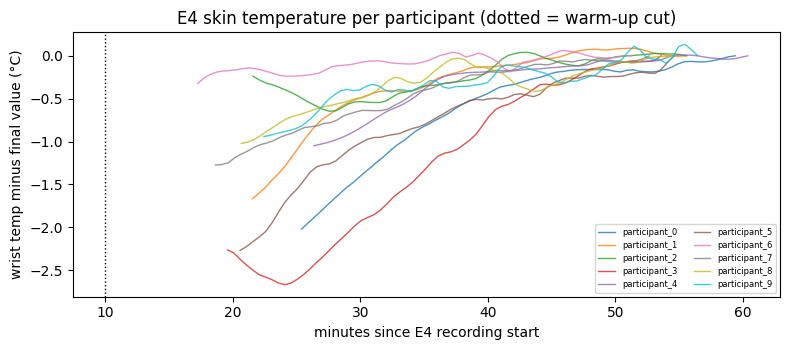

Temperature change during the first 10 min: mean +nan °C | range afterwards: mean 1.42 °C
rPPG signal chosen per window: {'pos_face': 288, 'chrom_face': 68, 'pos_forehead': 67, 'pos_cheek_l': 64, 'chrom_forehead': 59, 'chrom_cheek_l': 57, 'chrom_cheek_r': 56, 'pos_cheek_r': 31}


In [ ]:
# Wrist temperature over each E4 recording: is there a warm-up rise at the start?
fig, ax = plt.subplots(figsize=(8, 3.6))
for pid, g in WIN.groupby("pid"):
    ax.plot(g.e4_min, g.temp - g.temp.iloc[-1], lw=1, alpha=.8, label=pid)
ax.axvline(WARMUP_MIN, color="k", ls=":", lw=1)
ax.set(xlabel="minutes since E4 recording start", ylabel="wrist temp minus final value (°C)",
       title="E4 skin temperature per participant (dotted = warm-up cut)")
ax.legend(fontsize=6, ncol=2); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "w6_fig0_temp_warmup.png"), dpi=130); plt.show()
first = WIN[WIN.e4_min < WARMUP_MIN].groupby("pid").temp.agg(lambda x: x.iloc[-1] - x.iloc[0])
rest = WIN[WIN.e4_min >= WARMUP_MIN].groupby("pid").temp.agg(lambda x: x.max() - x.min())
print(f"Temperature change during the first {WARMUP_MIN:g} min: mean {first.mean():+.2f} °C | range afterwards: mean {rest.mean():.2f} °C")
print("rPPG signal chosen per window:", pd.Series([SIG_NAMES[int(k)] for k in WIN.rppg_sig.dropna() if k >= 0]).value_counts().head(8).to_dict())

In [ ]:
# Positive control: rPPG HR vs E4 HR (sync and rPPG quality check)
ref = "e4_hr" if "e4_hr" in WIN else "bvp_hr"
for col, lab in [("rppg_hr", "best-SNR signal"), ("rppg_hr_posface", "POS, whole face")]:
    ok = WIN[[col, ref]].dropna(); err = (ok[col] - ok[ref]).abs()
    print(f"rPPG HR ({lab}) vs {ref}: MAE {err.mean():.2f} BPM, within 5 BPM {np.mean(err<=5)*100:.0f}%, "
          f"Spearman {stats.spearmanr(ok[col], ok[ref])[0]:+.2f} (n={len(ok)})")
display(WIN.groupby("pid")[["rppg_hr", ref, "face_found"]].apply(lambda g: pd.Series({
    "rppg_vs_e4_MAE": (g.rppg_hr - g[ref]).abs().mean(), "face_found": g.face_found.mean()})).round(2))

rPPG HR (best-SNR signal) vs e4_hr: MAE 13.68 BPM, within 5 BPM 39%, Spearman -0.06 (n=690)
rPPG HR (POS, whole face) vs e4_hr: MAE 10.19 BPM, within 5 BPM 50%, Spearman +0.09 (n=690)


,rppg_vs_e4_MAE,face_found
pid,,
participant_0,11.35,1.00
participant_1,3.59,1.00
participant_2,7.90,1.00
participant_3,17.98,1.00
participant_4,10.37,0.99
participant_5,27.96,0.99
participant_6,10.26,1.00
participant_7,29.16,1.00
participant_8,5.18,1.00


## 5. Evaluation (leave-one-participant-out)
- Skill = % MAE reduction vs the reference, with a participant-bootstrap 95 % interval.
- `within_rho` = mean per-person Spearman between predicted and true series, i.e. how well the shape of each person's temperature curve is tracked.

In [ ]:
def make_models():
    return {"Ridge": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                               ("m", RidgeCV(alphas=np.logspace(-3, 3, 13)))]),
            "HGB": Pipeline([("imp", SimpleImputer(strategy="median")),
                             ("m", HistGradientBoostingRegressor(loss="absolute_error", max_iter=200, learning_rate=0.05,
                                                                 min_samples_leaf=10, random_state=SEED))])}

def boot_skill(am, ar, g, n=N_BOOT):
    _, inv = np.unique(g, return_inverse=True)
    sa, sb, c = np.bincount(inv, am), np.bincount(inv, ar), np.bincount(inv).astype(float)
    idx = np.random.default_rng(SEED).integers(0, len(c), (n, len(c)))
    with np.errstate(all="ignore"):
        sk = 100 * (1 - (sa[idx].sum(1) / c[idx].sum(1)) / (sb[idx].sum(1) / c[idx].sum(1)))
    sk = sk[np.isfinite(sk)]
    return np.percentile(sk, [2.5, 97.5]) if len(sk) else (np.nan, np.nan)

def within_rho(y, p, g):
    rs = [stats.spearmanr(y[g == k], p[g == k])[0] for k in np.unique(g) if (g == k).sum() >= 5 and np.std(p[g == k]) > 0]
    return np.nanmean(rs) if rs else np.nan

def lopo(df, cols, target, model):
    pred = np.full(len(df), np.nan); const = np.full(len(df), np.nan)
    for tr, te in LeaveOneGroupOut().split(df, groups=df["pid"]):
        y = df[target].iloc[tr]
        const[te] = y.median()
        if cols:
            m = make_models()[model].fit(df[cols].iloc[tr], y); pred[te] = m.predict(df[cols].iloc[te])
    return (pred if cols else const), const

def report(part, task, name, df, target, y_pred, y_ref, ref_name, model, show=True):
    y, g = df[target].to_numpy(), df["pid"].to_numpy()
    am, ar = np.abs(y - y_pred), np.abs(y - y_ref)
    lo, hi = boot_skill(am, ar, g)
    row = dict(part=part, task=task, features=name, model=model, n_windows=len(y), n_people=len(np.unique(g)),
               MAE=round(am.mean(), 4), ref=ref_name, ref_MAE=round(ar.mean(), 4),
               skill_pct=round(100 * (1 - am.mean() / ar.mean()), 1), skill_lo=round(lo, 1), skill_hi=round(hi, 1),
               within_rho=round(within_rho(y, y_pred, g), 3))
    RESULTS.append(row)
    if show:
        print(f"[{part}|{task}] {name:<26} {model:<5} MAE {row['MAE']:.3f} vs {ref_name} {row['ref_MAE']:.3f} -> "
              f"skill {row['skill_pct']:+.1f}% [{row['skill_lo']:+.1f}, {row['skill_hi']:+.1f}] | within-rho {row['within_rho']}")
    return row

def to_change(df, cols, base_min=BASE_MIN):
    """Express target and features as change from each person's first `base_min` minutes; drop those minutes."""
    out = []
    for pid, g in df.groupby("pid"):
        b = g[g.t_min < base_min]
        if len(b) == 0: continue
        h = g[g.t_min >= base_min].copy()
        for c in cols + ["temp"]:
            if c in h and c != "t_min": h[c] = h[c] - b[c].mean()
        out.append(h)
    return pd.concat(out, ignore_index=True) if out else df.iloc[:0]

def run_part(part, df, sets):
    for task in ("absolute", "change"):
        d = df if task == "absolute" else to_change(df, sorted({c for v in sets.values() for c in v}))
        if d.empty or d.pid.nunique() < 3:
            print(f"[{part}|{task}] skipped (too few participants)"); continue
        _, const = lopo(d, [], "temp", "Ridge")
        time_pred, _ = lopo(d, ["t_min"], "temp", "Ridge")
        report(part, task, "time only", d, "temp", time_pred, const, "constant", "Ridge")
        for name, cols in sets.items():
            cols = [c for c in cols if c in d]
            if not cols: continue
            for mn in make_models():
                p, _ = lopo(d, cols, "temp", mn)
                report(part, task, name, d, "temp", p, const, "constant", mn)
                if "t_min" in cols:
                    report(part, task, name, d, "temp", p, time_pred, "time only", mn)

RPPG = ["rppg_hr", "rppg_snr", "chrom_r", "chrom_g", "log_rg", "green_acdc", "face_found", "ectemp_rppg"]
CONTACT = ["bvp_hr", "bvp_snr", "bvp_amp", "e4_hr", "ectemp_e4"]
SETS_A = {"rPPG (face)": RPPG, "rPPG + time": RPPG + ["t_min"],
          "contact PPG (E4)": CONTACT, "contact PPG + time": CONTACT + ["t_min"],
          "ECTemp(rPPG HR) only": ["ectemp_rppg"]}
run_part("A Toadstool", WIN, SETS_A)

# Same analysis without the E4 warm-up period (time re-zeroed at the first kept window)
WIN_W = WIN[WIN.e4_min >= WARMUP_MIN].copy()
WIN_W["t_min"] = WIN_W.t_min - WIN_W.groupby("pid").t_min.transform("min")
print(f"\n--- without the first {WARMUP_MIN:g} min of each E4 recording: {len(WIN_W)} windows ---")
run_part(f"A Toadstool, warm-up {WARMUP_MIN:g} min dropped", WIN_W.reset_index(drop=True), SETS_A)

[A Toadstool|absolute] time only                  Ridge MAE 0.997 vs constant 1.018 -> skill +2.1% [-6.6, +11.4] | within-rho 0.931
[A Toadstool|absolute] rPPG (face)                Ridge MAE 1.269 vs constant 1.018 -> skill -24.6% [-68.8, +1.4] | within-rho 0.672
[A Toadstool|absolute] rPPG (face)                HGB   MAE 1.407 vs constant 1.018 -> skill -38.2% [-75.7, -17.3] | within-rho 0.515
[A Toadstool|absolute] rPPG + time                Ridge MAE 1.299 vs constant 1.018 -> skill -27.5% [-71.2, -1.9] | within-rho 0.684
[A Toadstool|absolute] rPPG + time                Ridge MAE 1.299 vs time only 0.997 -> skill -30.2% [-81.3, -2.3] | within-rho 0.684
[A Toadstool|absolute] rPPG + time                HGB   MAE 1.399 vs constant 1.018 -> skill -37.4% [-72.2, -17.3] | within-rho 0.545
[A Toadstool|absolute] rPPG + time                HGB   MAE 1.399 vs time only 0.997 -> skill -40.3% [-75.8, -19.1] | within-rho 0.545
[A Toadstool|absolute] contact PPG (E4)           Ridge MAE 1.077

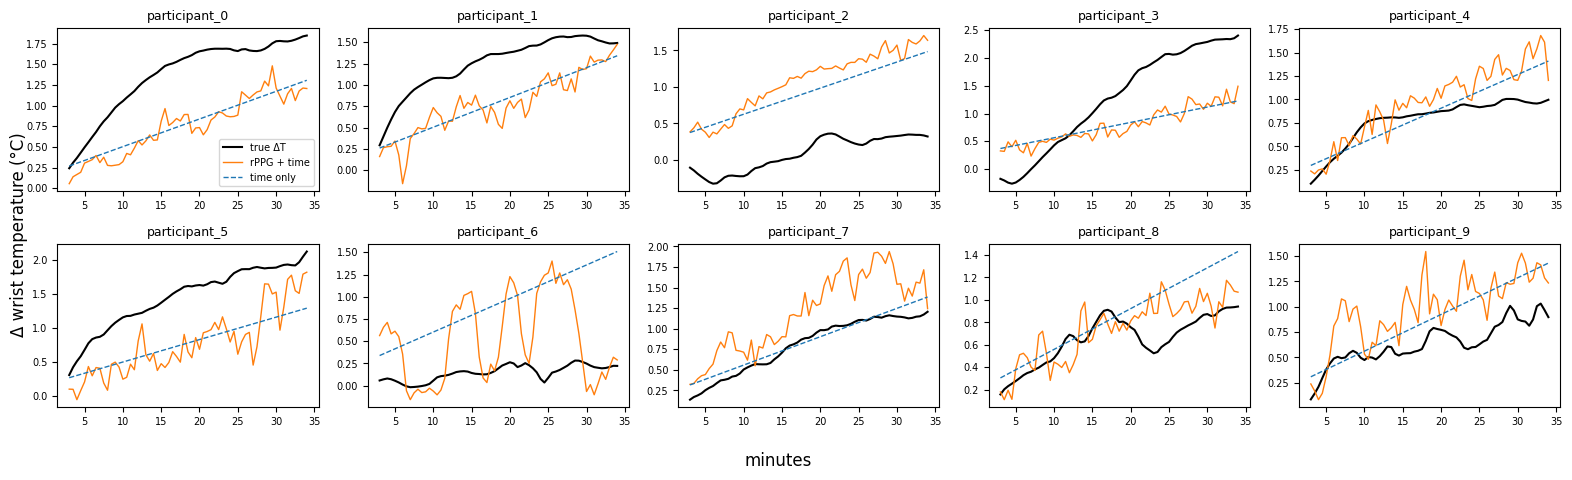

In [ ]:
# Per-person curves: true wrist temperature change vs LOPO prediction (rPPG + time, Ridge)
dch = to_change(WIN, sorted(set(RPPG + CONTACT)))
if not dch.empty:
    p_rppg, _ = lopo(dch, RPPG + ["t_min"], "temp", "Ridge"); p_time, _ = lopo(dch, ["t_min"], "temp", "Ridge")
    pids = dch.pid.unique(); n = len(pids); cols = min(5, n); rows = int(np.ceil(n / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(3.2 * cols, 2.4 * rows), squeeze=False)
    for ax, pid in zip(axs.ravel(), pids):
        m = (dch.pid == pid).to_numpy()
        ax.plot(dch.t_min[m], dch.temp[m], "k-", lw=1.5, label="true ΔT")
        ax.plot(dch.t_min[m], p_rppg[m], "-", color="tab:orange", lw=1, label="rPPG + time")
        ax.plot(dch.t_min[m], p_time[m], "--", color="tab:blue", lw=1, label="time only")
        ax.set_title(str(pid), fontsize=9); ax.tick_params(labelsize=7)
    for ax in axs.ravel()[n:]: ax.axis("off")
    axs[0, 0].legend(fontsize=7); fig.supxlabel("minutes"); fig.supylabel("Δ wrist temperature (°C)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "w6_fig1_toadstool_curves.png"), dpi=130); plt.show()

## Part B: contact PPG → wrist temperature on the PhysioNet wearable-device dataset (open)
More people and real physiological load (cycling), but **no video**. This is a feasibility test: if even contact PPG cannot track wrist-temperature changes during exercise, rPPG will not either. Each protocol (stress / aerobic / anaerobic) is analysed separately, with LOPO by subject. Set `W6_RUN_PART_B=0` to skip.

In [ ]:
WINB = pd.DataFrame()
if RUN_PART_B:
    pz = PHYSIO_ZIP_LOCAL or os.path.join(LOCAL, "wearable_device_dataset.zip")
    if not os.path.exists(pz):
        print("Downloading PhysioNet wearable-device-dataset ...")
        r = subprocess.run(["wget", "-c", "-q", "--show-progress", "-O", pz, PHYSIO_ZIP_URL]); assert r.returncode == 0
    proot = os.path.join(LOCAL, "wearable_device_dataset")
    if not glob.glob(os.path.join(proot, "**", "TEMP.csv"), recursive=True):
        with zipfile.ZipFile(pz) as z:
            for m in z.infolist():
                if m.filename.lower().endswith(".csv"): z.extract(m, proot)
    rows = []
    for tfile in sorted(glob.glob(os.path.join(proot, "**", "TEMP.csv"), recursive=True)):
        d = os.path.dirname(tfile)
        if not os.path.exists(os.path.join(d, "BVP.csv")): continue
        rel = os.path.relpath(d, proot).split(os.sep)
        proto = next((x.upper() for x in rel if re.fullmatch(r"stress|aerobic|anaerobic", x, re.I)), "UNKNOWN")
        e4 = load_e4(d, verbose=False)
        if "TEMP" not in e4 or "BVP" not in e4: continue
        w = window_table({"e4": e4}, f"{proto}_{rel[-1]}", use_video=False); w["protocol"] = proto
        rows.append(w)
    WINB = pd.concat(rows, ignore_index=True).dropna(subset=["temp"]) if rows else pd.DataFrame()
    n0 = len(WINB); WINB = WINB[WINB.temp.between(25, 40)].reset_index(drop=True)
    print(f"Dropped {n0 - len(WINB)} windows with wrist temperature outside 25-40 °C (band off the wrist)")
    print(f"Part B: {len(WINB)} windows | " + ", ".join(f"{k}: {v} people" for k, v in WINB.groupby("protocol").pid.nunique().items()))
    SETS_B = {"contact PPG (E4)": CONTACT, "contact PPG + time": CONTACT + ["t_min"], "ECTemp(E4 HR) only": ["ectemp_e4"]}
    for proto, g in WINB.groupby("protocol"):
        run_part(f"B {proto}", g.reset_index(drop=True), SETS_B)

Dropped 148 windows with wrist temperature outside 25-40 °C (band off the wrist)
Part B: 6657 windows | AEROBIC: 30 people, ANAEROBIC: 32 people, STRESS: 37 people
[B AEROBIC|absolute] time only                  Ridge MAE 1.380 vs constant 1.378 -> skill -0.2% [-1.9, +2.0] | within-rho 0.078
[B AEROBIC|absolute] contact PPG (E4)           Ridge MAE 1.307 vs constant 1.378 -> skill +5.2% [-2.6, +12.9] | within-rho 0.087
[B AEROBIC|absolute] contact PPG (E4)           HGB   MAE 1.538 vs constant 1.378 -> skill -11.6% [-27.4, -0.5] | within-rho 0.042
[B AEROBIC|absolute] contact PPG + time         Ridge MAE 1.320 vs constant 1.378 -> skill +4.2% [-5.4, +13.6] | within-rho 0.048
[B AEROBIC|absolute] contact PPG + time         Ridge MAE 1.320 vs time only 1.380 -> skill +4.3% [-4.7, +13.0] | within-rho 0.048
[B AEROBIC|absolute] contact PPG + time         HGB   MAE 1.524 vs constant 1.378 -> skill -10.6% [-27.5, +1.8] | within-rho 0.022
[B AEROBIC|absolute] contact PPG + time         HGB   

## 6. Results, benchmarks and decision gate

In [ ]:
res = pd.DataFrame(RESULTS); res.to_csv(os.path.join(OUT_DIR, "w6_results.csv"), index=False)
display(res)

bench = pd.DataFrame([
    dict(source="Clinical thermometer standard (ASTM E1965 / ISO 80601-2-56)", target="body", error="±0.2 °C lab accuracy"),
    dict(source="FDA guidance / IEC 80601-2-59 screening thermograph", target="body (skin-based)", error="≤ ±0.5 °C lab accuracy"),
    dict(source="Non-contact IR thermometers, 1,113 adults (Sci Rep 2021)", target="body", error="bias −0.9 to +0.2 °C"),
    dict(source="FeverPhone (UW 2023), 37 ED patients", target="core (oral ref.)", error="MAE 0.229 °C"),
    dict(source="Buller 2013 / biphasic KF (Falcone 2024), HR → core", target="core (pill)", error="RMSE 0.34 / 0.28 °C"),
    dict(source="MCD-rPPG: our best (week 5) vs constant", target="body (non-contact)", error="0.0936 vs 0.093 °C"),
])
best = res[res.ref == "constant"].sort_values("MAE").groupby(["part", "task"]).head(1)
for r in best.itertuples():
    bench.loc[len(bench)] = dict(source=f"This work, week 6: {r.part} {r.task}, {r.features} ({r.model})",
                                 target="wrist skin", error=f"MAE {r.MAE:.3f} vs constant {r.ref_MAE:.3f} °C "
                                 f"(skill {r.skill_pct:+.1f}% [{r.skill_lo:+.1f}, {r.skill_hi:+.1f}])")
bench.to_csv(os.path.join(OUT_DIR, "w6_benchmarks.csv"), index=False); display(bench)

,part,task,features,model,n_windows,n_people,MAE,ref,ref_MAE,skill_pct,skill_lo,skill_hi,within_rho
0,A Toadstool,absolute,time only,Ridge,690,10,0.9974,constant,1.0184,2.1,-6.6,11.4,0.931
1,A Toadstool,absolute,rPPG (face),Ridge,690,10,1.2688,constant,1.0184,-24.6,-68.8,1.4,0.672
2,A Toadstool,absolute,rPPG (face),HGB,690,10,1.4075,constant,1.0184,-38.2,-75.7,-17.3,0.515
3,A Toadstool,absolute,rPPG + time,Ridge,690,10,1.2989,constant,1.0184,-27.5,-71.2,-1.9,0.684
4,A Toadstool,absolute,rPPG + time,Ridge,690,10,1.2989,time only,0.9974,-30.2,-81.3,-2.3,0.684
...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,B STRESS,change,contact PPG + time,Ridge,2823,37,1.1997,time only,1.0939,-9.7,-24.6,1.3,-0.040
110,B STRESS,change,contact PPG + time,HGB,2823,37,1.3990,constant,1.0643,-31.4,-59.2,-12.4,-0.131
111,B STRESS,change,contact PPG + time,HGB,2823,37,1.3990,time only,1.0939,-27.9,-55.1,-9.8,-0.131
112,B STRESS,change,ECTemp(E4 HR) only,Ridge,2823,37,1.0953,constant,1.0643,-2.9,-14.3,6.4,-0.041


,source,target,error
0,Clinical thermometer standard (ASTM E1965 / IS...,body,±0.2 °C lab accuracy
1,FDA guidance / IEC 80601-2-59 screening thermo...,body (skin-based),≤ ±0.5 °C lab accuracy
2,"Non-contact IR thermometers, 1,113 adults (Sci...",body,bias −0.9 to +0.2 °C
3,"FeverPhone (UW 2023), 37 ED patients",core (oral ref.),MAE 0.229 °C
4,"Buller 2013 / biphasic KF (Falcone 2024), HR →...",core (pill),RMSE 0.34 / 0.28 °C
5,MCD-rPPG: our best (week 5) vs constant,body (non-contact),0.0936 vs 0.093 °C
6,"This work, week 6: A Toadstool change, ECTemp(...",wrist skin,MAE 0.467 vs constant 0.530 °C (skill +12.0% [...
7,"This work, week 6: A Toadstool, warm-up 10 min...",wrist skin,MAE 0.467 vs constant 0.530 °C (skill +12.0% [...
8,"This work, week 6: B ANAEROBIC change, time on...",wrist skin,MAE 0.906 vs constant 0.881 °C (skill -2.8% [-...
9,"This work, week 6: A Toadstool absolute, time ...",wrist skin,MAE 0.997 vs constant 1.018 °C (skill +2.1% [-...


### How to read this
- **Positive control:** rPPG HR should agree with E4 HR within a few BPM. If not, the sync or the face video quality is the problem; fix that first.
- **Task 1 (absolute):** expected to fail. Wrist temperature differs between people for reasons a face cannot see (room, clothing, the wristband's fit).
- **Task 2 (change):** the realistic target. The question is whether `rPPG + time` beats `time only` (row with `ref = time only`). Beating only the constant may just be drift with time.
- **Contact PPG (Part A ceiling and Part B):** if contact PPG + time does not beat time only, the pulse carries no wrist-temperature information beyond drift, and rPPG cannot either.

### Decision gate
1. **rPPG + time beats time only (interval above 0) on Task 2:** first positive temperature result. Report it as *tracking skin-temperature change*, not as body temperature. Next, try SpeakingFaces (RGB → thermal facial temperature, with audio).
2. **Contact PPG works but rPPG doesn't:** the limit is rPPG signal quality (motion while gaming) → better ROI, motion filtering, a stronger rPPG model.
3. **Neither works:** pulse does not track skin temperature at this time scale. The temperature conclusion for the project is then firm: camera-based temperature needs a thermal sensor or data with real fever.